In [1]:
# Cell 1: Load Iris data and prepare a DataFrame view
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
label_names = iris.target_names

iris_df = pd.DataFrame(X, columns=feature_names)
iris_df["target"] = y

print("Iris shape:", iris_df.shape)
print(iris_df.head())

Iris shape: (150, 5)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [2]:
# Cell 2: Standardize features and project data to 2 principal components
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

reduced_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
reduced_df["target"] = y

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum().round(4))

Explained variance ratio: [0.72962445 0.22850762]
Total explained variance: 0.9581


In [3]:
# Cell 3: Summarize explained and cumulative variance
variance_df = pd.DataFrame({
    "Component": ["PC1", "PC2"],
    "Explained Variance Ratio": pca.explained_variance_ratio_,
    "Cumulative Variance": np.cumsum(pca.explained_variance_ratio_),
})

print(variance_df)

  Component  Explained Variance Ratio  Cumulative Variance
0       PC1                  0.729624             0.729624
1       PC2                  0.228508             0.958132


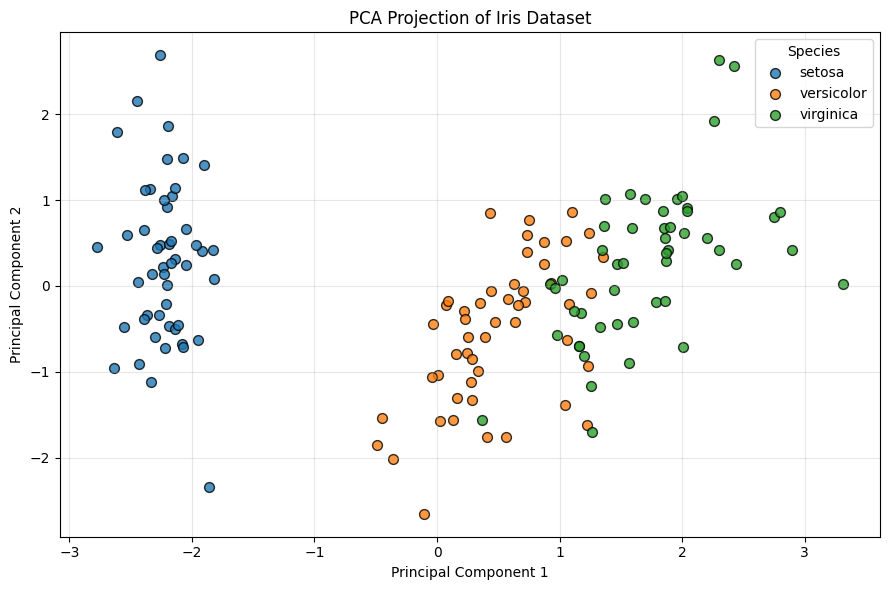

In [4]:
# Cell 4: Plot 2D PCA projection colored by species
plt.figure(figsize=(9, 6))
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

for class_id, class_name in enumerate(label_names):
    class_points = reduced_df[reduced_df["target"] == class_id]
    plt.scatter(
        class_points["PC1"],
        class_points["PC2"],
        label=class_name,
        color=colors[class_id],
        alpha=0.8,
        edgecolor="black",
        s=50,
    )

plt.title("PCA Projection of Iris Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Species")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# Cell 5: Show PCA loadings to interpret feature influence
loadings_df = pd.DataFrame(
    pca.components_.T,
    columns=["PC1_loading", "PC2_loading"],
    index=feature_names,
)

print(loadings_df)

                   PC1_loading  PC2_loading
sepal length (cm)     0.521066     0.377418
sepal width (cm)     -0.269347     0.923296
petal length (cm)     0.580413     0.024492
petal width (cm)      0.564857     0.066942


In [6]:
# Cell 6: Rank features by total absolute loading across PCs
contribution_df = loadings_df.abs()
contribution_df["Total_Contribution"] = contribution_df.sum(axis=1)

print(contribution_df.sort_values("Total_Contribution", ascending=False))

                   PC1_loading  PC2_loading  Total_Contribution
sepal width (cm)      0.269347     0.923296            1.192643
sepal length (cm)     0.521066     0.377418            0.898484
petal width (cm)      0.564857     0.066942            0.631799
petal length (cm)     0.580413     0.024492            0.604905
